# 03 — Đánh giá Baseline YOLOv8n (không train lại)

Notebook này dùng checkpoint đã train trên server (`best.pt`) để:
1. Xem lại metric / đường cong đã lưu
2. Chạy lại validation (và tuỳ chọn test)
3. Xem prediction trên ảnh valid / ảnh nhiều tờ
4. Kết luận: baseline đã ổn chưa, cần cải tiến gì tiếp

> **Không** chạy lại `02_Train_YOLO_Baseline.ipynb` từ đầu trừ khi bạn cố ý muốn train lại.

In [2]:
from pathlib import Path
import json
import random

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from PIL import Image
import torch
from ultralytics import YOLO

sns.set_theme(style="whitegrid", context="notebook")
SEED = 42
random.seed(SEED)
np.random.seed(SEED)

NOTEBOOK_DIR = Path(".").resolve()
PROJECT_DIR = NOTEBOOK_DIR.parent
RUN_DIR = PROJECT_DIR / "runs" / "detect" / "vn_currency_yolov8n_baseline"
BEST_PT = RUN_DIR / "weights" / "best.pt"
EXPORT_BEST = NOTEBOOK_DIR / "baseline_exports" / "yolov8n_baseline_best.pt"
CLEAN_YAML = PROJECT_DIR / "datasets" / "vn_currency_yolo_bbox" / "data.yaml"
EXPORT_DIR = NOTEBOOK_DIR / "baseline_exports"

WEIGHT = BEST_PT if BEST_PT.exists() else EXPORT_BEST
assert WEIGHT.exists(), f"Không thấy checkpoint: {BEST_PT} hoặc {EXPORT_BEST}"
assert CLEAN_YAML.exists(), f"Thiếu {CLEAN_YAML} — chạy convert dataset trước"

DEVICE = 0 if torch.cuda.is_available() else "cpu"
IMGSZ = 640
CONF = 0.25  # ngưỡng tạm để xem; tối ưu theo cost làm ở notebook cải tiến

print("WEIGHT :", WEIGHT)
print("YAML   :", CLEAN_YAML)
print("RUN_DIR:", RUN_DIR)
print("DEVICE :", DEVICE, "|", torch.cuda.get_device_name(0) if torch.cuda.is_available() else "CPU")

Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/home/dungtv/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings
WEIGHT : /home/dungtv/Desktop/Note/Hoc_Tap/Nhan_dang_mau/nhan_dang_tien_Viet_Nam/runs/detect/vn_currency_yolov8n_baseline/weights/best.pt
YAML   : /home/dungtv/Desktop/Note/Hoc_Tap/Nhan_dang_mau/nhan_dang_tien_Viet_Nam/datasets/vn_currency_yolo_bbox/data.yaml
RUN_DIR: /home/dungtv/Desktop/Note/Hoc_Tap/Nhan_dang_mau/nhan_dang_tien_Viet_Nam/runs/detect/vn_currency_yolov8n_baseline
DEVICE : 0 | NVIDIA GeForce RTX 5060


## 1. Metric đã lưu từ lần train trên server

,model,val_mAP50,val_mAP50-95,val_precision,val_recall
0,YOLOv8n baseline (A0),0.994649,0.93148,0.989089,0.9953


epochs: 50 | batch: 32 | imgsz: 640
class_names: ['1000', '10000', '100000', '2000', '20000', '200000', '5000', '50000', '500000']
VAL từ train: {'mAP50': 0.9946490363727312, 'mAP50-95': 0.9314799420259111, 'precision': 0.9890893683542425, 'recall': 0.9952998461634114, 'AP50_1000': 0.995, 'AP50_10000': 0.9918413273545812, 'AP50_100000': 0.995, 'AP50_2000': 0.995, 'AP50_20000': 0.995, 'AP50_200000': 0.995, 'AP50_5000': 0.995, 'AP50_50000': 0.995, 'AP50_500000': 0.995}


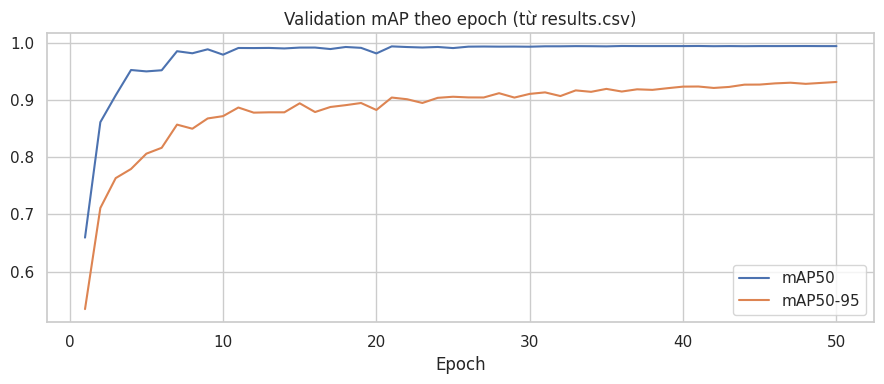

,epoch,time,train/box_loss,train/cls_loss,train/dfl_loss,metrics/precision(B),metrics/recall(B),metrics/mAP50(B),metrics/mAP50-95(B),val/box_loss,val/cls_loss,val/dfl_loss,lr/pg0,lr/pg1,lr/pg2
47,48,127.087,0.41831,0.28157,0.89176,0.99160,0.99475,0.99480,0.92860,0.36586,0.19470,0.83607,0.000053,0.000053,0.000053
48,49,129.356,0.36516,0.20237,0.84058,0.99034,0.99456,0.99468,0.93025,0.36168,0.19244,0.83456,0.000038,0.000038,0.000038
49,50,131.645,0.38741,0.20347,0.87678,0.98910,0.99530,0.99465,0.93189,0.36147,0.19169,0.83401,0.000023,0.000023,0.000023


In [3]:
metrics_csv = EXPORT_DIR / "baseline_val_metrics.csv"
meta_json = EXPORT_DIR / "baseline_run_meta.json"
results_csv = RUN_DIR / "results.csv"

if metrics_csv.exists():
    display(pd.read_csv(metrics_csv))
if meta_json.exists():
    meta = json.loads(meta_json.read_text(encoding="utf-8"))
    print("epochs:", meta.get("epochs"), "| batch:", meta.get("batch"), "| imgsz:", meta.get("imgsz"))
    print("class_names:", meta.get("class_names"))
    print("VAL từ train:", meta.get("val"))

if results_csv.exists():
    hist = pd.read_csv(results_csv)
    hist.columns = [c.strip() for c in hist.columns]
    epoch_col = "epoch" if "epoch" in hist.columns else hist.columns[0]
    map50_col = next((c for c in hist.columns if "mAP50(B)" in c or ("mAP50" in c and "95" not in c)), None)
    map5095_col = next((c for c in hist.columns if "mAP50-95" in c), None)

    fig, ax = plt.subplots(figsize=(9, 4))
    if map50_col:
        ax.plot(hist[epoch_col], hist[map50_col], label="mAP50")
    if map5095_col:
        ax.plot(hist[epoch_col], hist[map5095_col], label="mAP50-95")
    ax.set_title("Validation mAP theo epoch (từ results.csv)")
    ax.set_xlabel("Epoch")
    ax.legend()
    plt.tight_layout()
    plt.show()
    display(hist.tail(3))

## 2. Xem plots Ultralytics đã xuất sẵn

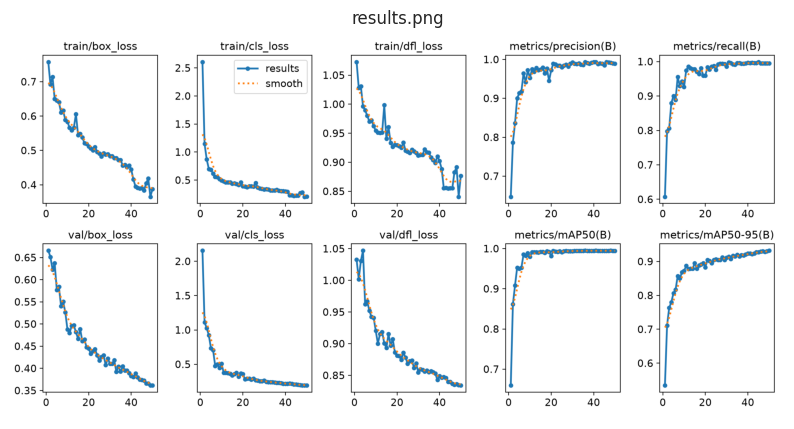

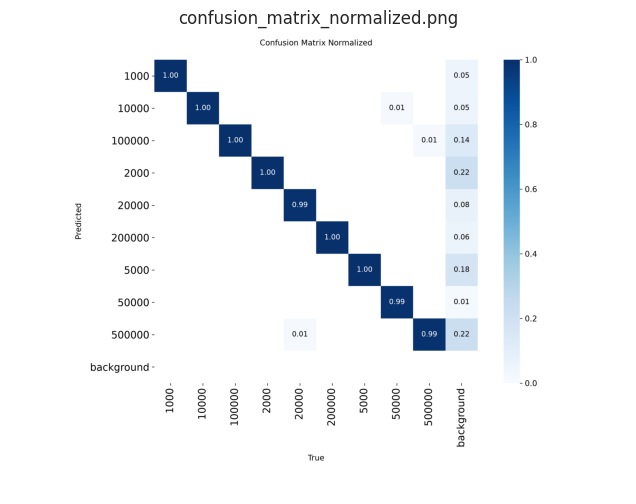

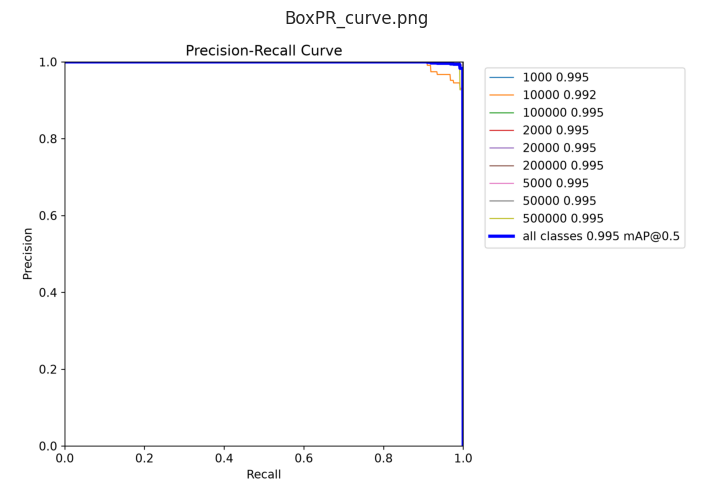

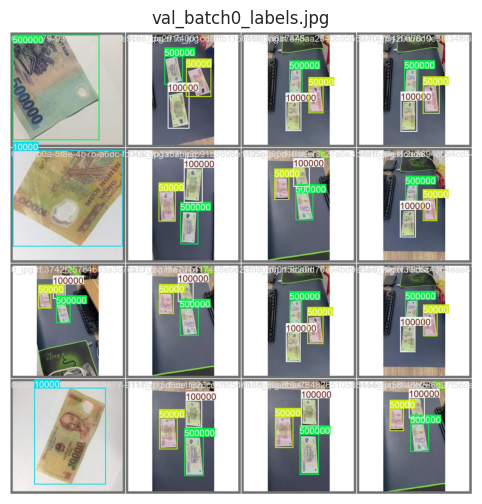

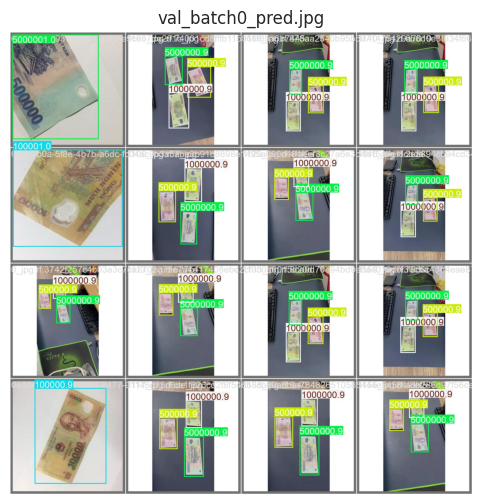

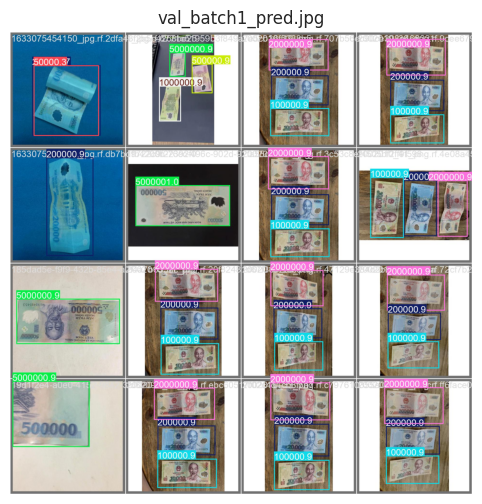

In [4]:
plot_names = [
    "results.png",
    "confusion_matrix_normalized.png",
    "BoxPR_curve.png",
    "val_batch0_labels.jpg",
    "val_batch0_pred.jpg",
    "val_batch1_pred.jpg",
]

for name in plot_names:
    p = RUN_DIR / name
    if not p.exists():
        print("Thiếu:", name)
        continue
    img = Image.open(p)
    plt.figure(figsize=(10, 6))
    plt.imshow(img)
    plt.axis("off")
    plt.title(name)
    plt.show()

## 3. Đánh giá lại trên validation (máy local)

Ultralytics 8.4.197 🚀 Python-3.10.12 torch-2.14.1+cu130 CUDA:0 (NVIDIA GeForce RTX 5060, 7697MiB)
Model summary (fused): 73 layers, 3,134,651 parameters, 0 gradients, 8.6 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 2311.2±883.6 MB/s, size: 39.7 KB)
val: Scanning /home/dungtv/Desktop/Note/Hoc_Tap/Nhan_dang_mau/nhan_dang_tien_Viet_Nam/datasets/vn_currency_yolo_bbox/valid/labels... 439 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 439/439 2.7Kit/s 0.2s<0.3s
val: New cache created: /home/dungtv/Desktop/Note/Hoc_Tap/Nhan_dang_mau/nhan_dang_tien_Viet_Nam/datasets/vn_currency_yolo_bbox/valid/labels.cache
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 28/28 12.8it/s 2.2s0.1s
                   all        439       1074      0.989      0.995      0.995      0.931
                  1000        120        120      0.997          1      0.995      0.959
                 10000        122        122      0.945      0.979

,class,AP50
1,10000,0.991841
0,1000,0.995000
2,100000,0.995000
3,2000,0.995000
4,20000,0.995000
5,200000,0.995000
6,5000,0.995000
7,50000,0.995000
8,500000,0.995000


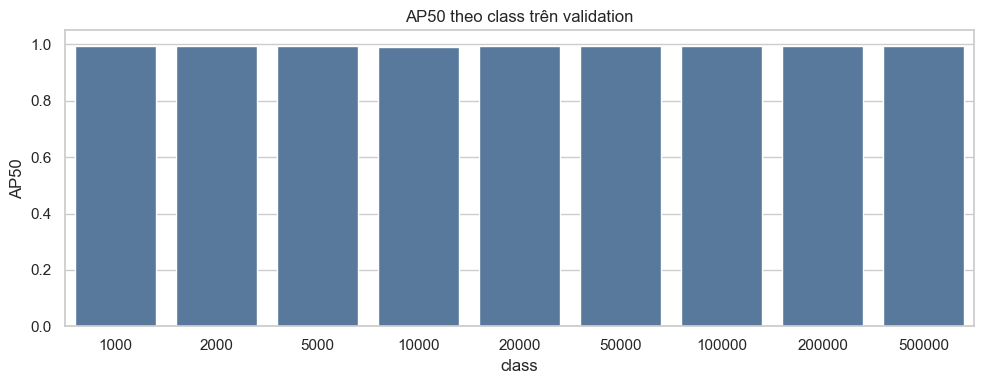

In [5]:
model = YOLO(str(WEIGHT))

val_metrics = model.val(
    data=str(CLEAN_YAML),
    split="val",
    imgsz=IMGSZ,
    device=DEVICE,
    plots=True,
    verbose=True,
)

box = val_metrics.box
baseline_val = {
    "mAP50": float(box.map50),
    "mAP50-95": float(box.map),
    "precision": float(box.mp),
    "recall": float(box.mr),
}
print("VAL:", baseline_val)

# Per-class AP50
names = model.names if isinstance(model.names, dict) else {i: n for i, n in enumerate(model.names)}
if getattr(box, "ap50", None) is not None:
    ap50 = np.array(box.ap50).reshape(-1)
    rows = []
    for i, ap in enumerate(ap50):
        rows.append({"class": names.get(i, str(i)), "AP50": float(ap)})
    per_class = pd.DataFrame(rows).sort_values("AP50")
    display(per_class)

    fig, ax = plt.subplots(figsize=(10, 4))
    sns.barplot(data=per_class.sort_values("class", key=lambda s: s.map(lambda x: int(x))), x="class", y="AP50", ax=ax, color="#4C78A8")
    ax.set_ylim(0, 1.05)
    ax.set_title("AP50 theo class trên validation")
    plt.tight_layout()
    plt.show()

### 3.1. (Tuỳ chọn) Xem nhanh test — chỉ tham khảo, chưa khóa so sánh cuối

In [6]:
RUN_TEST_NOW = True  # đổi False nếu muốn giữ test cho lần so sánh cuối

baseline_test = None
if RUN_TEST_NOW:
    test_metrics = model.val(
        data=str(CLEAN_YAML),
        split="test",
        imgsz=IMGSZ,
        device=DEVICE,
        plots=False,
        verbose=True,
    )
    tbox = test_metrics.box
    baseline_test = {
        "mAP50": float(tbox.map50),
        "mAP50-95": float(tbox.map),
        "precision": float(tbox.mp),
        "recall": float(tbox.mr),
    }
    print("TEST (tham khảo):", baseline_test)
else:
    print("Bỏ qua test.")

Ultralytics 8.4.197 🚀 Python-3.10.12 torch-2.14.1+cu130 CUDA:0 (NVIDIA GeForce RTX 5060, 7697MiB)
Model summary (fused): 73 layers, 3,134,651 parameters, 0 gradients, 8.6 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 3095.9±1748.6 MB/s, size: 54.8 KB)
val: Scanning /home/dungtv/Desktop/Note/Hoc_Tap/Nhan_dang_mau/nhan_dang_tien_Viet_Nam/datasets/vn_currency_yolo_bbox/test/labels... 218 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 218/218 4.1Kit/s 0.1s
val: New cache created: /home/dungtv/Desktop/Note/Hoc_Tap/Nhan_dang_mau/nhan_dang_tien_Viet_Nam/datasets/vn_currency_yolo_bbox/test/labels.cache
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 14/14 14.5it/s 1.0s0.1s
                   all        218        558      0.991      0.995      0.993       0.92
                  1000         68         68      0.996          1      0.995      0.951
                 10000         57         57      0.976          1      

## 4. Inference trực quan

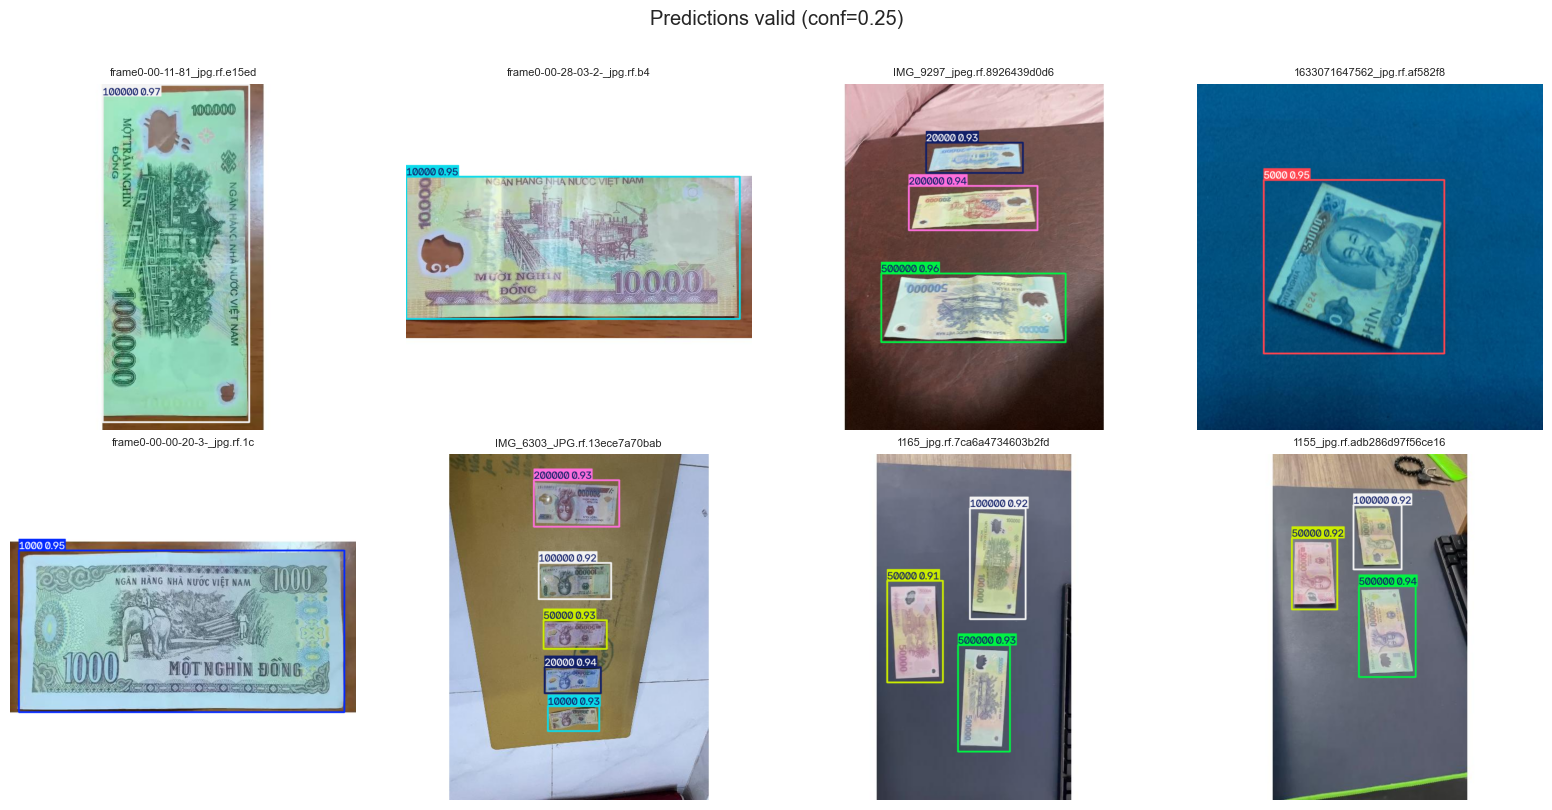

In [7]:
val_img_dir = PROJECT_DIR / "datasets" / "vn_currency_yolo_bbox" / "valid" / "images"
val_lbl_dir = PROJECT_DIR / "datasets" / "vn_currency_yolo_bbox" / "valid" / "labels"
val_images = sorted([p for p in val_img_dir.iterdir() if p.suffix.lower() in {".jpg", ".jpeg", ".png"}])

sample = random.sample(val_images, k=min(8, len(val_images)))
preds = model.predict(source=[str(p) for p in sample], imgsz=IMGSZ, conf=CONF, device=DEVICE, verbose=False)

fig, axes = plt.subplots(2, 4, figsize=(16, 8))
axes = axes.ravel()
for ax, r in zip(axes, preds):
    ax.imshow(r.plot()[:, :, ::-1])
    ax.set_title(Path(r.path).name[:28], fontsize=8)
    ax.axis("off")
for ax in axes[len(preds):]:
    ax.axis("off")
plt.suptitle(f"Predictions valid (conf={CONF})", y=1.01)
plt.tight_layout()
plt.show()

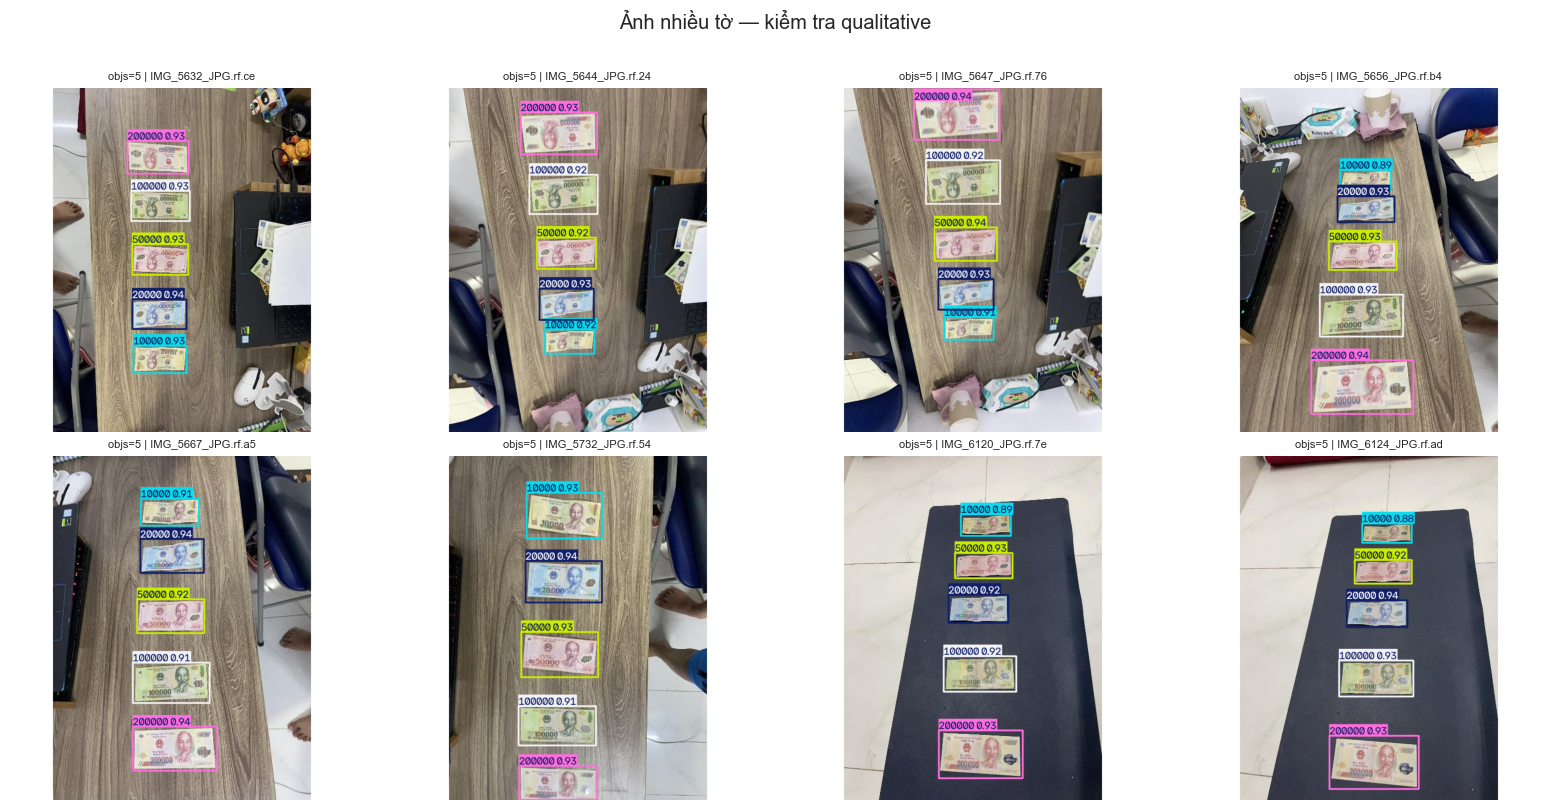

In [8]:
def count_objects(stem: str) -> int:
    lp = val_lbl_dir / f"{stem}.txt"
    if not lp.exists():
        return 0
    return sum(1 for ln in lp.read_text().splitlines() if ln.strip())

hard = sorted(
    [(count_objects(p.stem), p) for p in val_images],
    key=lambda x: -x[0],
)
hard_imgs = [p for n, p in hard if n >= 3][:8]
if not hard_imgs:
    hard_imgs = [p for _, p in hard[:8]]

hard_preds = model.predict(source=[str(p) for p in hard_imgs], imgsz=IMGSZ, conf=CONF, device=DEVICE, verbose=False)
fig, axes = plt.subplots(2, 4, figsize=(16, 8))
axes = axes.ravel()
for ax, r, p in zip(axes, hard_preds, hard_imgs):
    ax.imshow(r.plot()[:, :, ::-1])
    ax.set_title(f"objs={count_objects(p.stem)} | {p.name[:18]}", fontsize=8)
    ax.axis("off")
for ax in axes[len(hard_preds):]:
    ax.axis("off")
plt.suptitle("Ảnh nhiều tờ — kiểm tra qualitative", y=1.01)
plt.tight_layout()
plt.show()

## 5. Checklist: baseline đã OK chưa?

In [9]:
print("===== Nhận xét nhanh =====")
print(f"VAL  mAP50={baseline_val['mAP50']:.4f} | mAP50-95={baseline_val['mAP50-95']:.4f} | P={baseline_val['precision']:.4f} | R={baseline_val['recall']:.4f}")
if baseline_test:
    print(f"TEST mAP50={baseline_test['mAP50']:.4f} | mAP50-95={baseline_test['mAP50-95']:.4f} | P={baseline_test['precision']:.4f} | R={baseline_test['recall']:.4f}")

print(
    """
Cách đọc kết quả:
- mAP50 ~0.99 trên val là RẤT CAO cho baseline → đủ làm mốc A0, không cần train lại YOLOv8n cùng setting.
- Vẫn nên nhìn confusion matrix + ảnh nhiều tờ: class nào hay nhầm (vd 10000), box có ôm sát không.
- Nếu test cũng cao tương tự → dataset khá "dễ" / đồng nhất; cải tiến nên tập trung demo thực tế + threshold/cost + phân tích lỗi,
  hơn là train thêm epoch cùng model.
- Nếu test tụt rõ so với val → có dấu hiệu overfit / lệch phân phối → ưu tiên augment / dữ liệu khó hơn.

Việc nên làm tiếp (notebook 04):
1) A1: augment mạnh hơn / làm sạch outlier nhãn (nếu còn lỗi qualitative)
2) A3: sweep conf trên VAL theo chi phí FP/FN
3) (Tuỳ chọn) A2: YOLOv8s nếu muốn so capacity
4) Demo inference ảnh tự chụp ngoài dataset
"""
)

===== Nhận xét nhanh =====
VAL  mAP50=0.9946 | mAP50-95=0.9315 | P=0.9891 | R=0.9953
TEST mAP50=0.9926 | mAP50-95=0.9201 | P=0.9909 | R=0.9953

Cách đọc kết quả:
- mAP50 ~0.99 trên val là RẤT CAO cho baseline → đủ làm mốc A0, không cần train lại YOLOv8n cùng setting.
- Vẫn nên nhìn confusion matrix + ảnh nhiều tờ: class nào hay nhầm (vd 10000), box có ôm sát không.
- Nếu test cũng cao tương tự → dataset khá "dễ" / đồng nhất; cải tiến nên tập trung demo thực tế + threshold/cost + phân tích lỗi,
  hơn là train thêm epoch cùng model.
- Nếu test tụt rõ so với val → có dấu hiệu overfit / lệch phân phối → ưu tiên augment / dữ liệu khó hơn.

Việc nên làm tiếp (notebook 04):
1) A1: augment mạnh hơn / làm sạch outlier nhãn (nếu còn lỗi qualitative)
2) A3: sweep conf trên VAL theo chi phí FP/FN
3) (Tuỳ chọn) A2: YOLOv8s nếu muốn so capacity
4) Demo inference ảnh tự chụp ngoài dataset

